# Feature Engineering

## Loading Data

In [1]:
import pandas as pd

df = pd.read_csv(
    "../../../assets/datasets/1_UCI_Chronic_Kidney_Disease_Dataset/1_cleaned_data/DS1_cleaned.csv"
)

df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [2]:
df_fe = df.copy()

print("Original dataset shape:", df.shape)
print("Feature engineering dataset shape:", df_fe.shape)

Original dataset shape: (400, 25)
Feature engineering dataset shape: (400, 25)



## Feature Engineering 1: Comorbidity Count

### Objective
Create a new feature called `comorbidity_count` by combining three existing medical condition variables: hypertension (`htn`), diabetes mellitus (`dm`), and coronary artery disease (`cad`).

The purpose is to represent the number of these coexisting medical conditions for each patient in a single numerical feature.

### Feature Description

| Original Feature | Description | Encoding |
|---|---|---|
| `htn` | Hypertension | Yes = 1, No = 0 |
| `dm` | Diabetes mellitus | Yes = 1, No = 0 |
| `cad` | Coronary artery disease | Yes = 1, No = 0 |

### Calculation


The new feature is calculated by summing the three binary variables:

$$
\text{Comorbidity Count} = htn + dm + cad
$$

The resulting value ranges from 0 to 3.

### Example

| htn | dm | cad | comorbidity_count |
|---|---|---|---|
| 1 | 1 | 0 | 2 |
| 1 | 0 | 0 | 1 |
| 0 | 0 | 0 | 0 |
| 1 | 1 | 1 | 3 |

### Handling Missing Values

Records with missing values in any of the three original variables are assigned `NaN` for the new feature. This avoids incorrectly treating unknown medical conditions as absent.

### Expected Benefit

This feature may help capture the combined presence of multiple medical conditions rather than considering each condition independently. Its contribution will be evaluated during feature selection and model performance comparison.

**Note:** The target variable (`class`) is not used in the calculation of this feature.


### Convert categorical values into numerical values

In [3]:
binary_mapping = {
    "yes": 1,
    "no": 0
}

comorbidity_columns = ["htn", "dm", "cad"]

comorbidity_encoded = df_fe[comorbidity_columns].apply(
    lambda col: col.str.strip().str.lower().map(binary_mapping)
)

### Create the new feature

In [4]:
df_fe["comorbidity_count"] = comorbidity_encoded.sum(
    axis=1,
    min_count=3
)

### Check the results

In [5]:
print("New feature distribution:")

print(
    df_fe["comorbidity_count"]
    .value_counts(dropna=False)
    .sort_index()
)

New feature distribution:
comorbidity_count
0.0    218
1.0     66
2.0     90
3.0     24
NaN      2
Name: count, dtype: int64


In [6]:
display(
    pd.crosstab(
        df_fe["comorbidity_count"],
        df_fe["class"]
    )
)

class,ckd,notckd
comorbidity_count,,
0.0,70,148
1.0,66,0
2.0,90,0
3.0,24,0


In [7]:
# Examine individual comorbidity features
for col in ["htn", "dm", "cad"]:

    print(f"\nDistribution of {col}:")
    print(df_fe[col].value_counts(dropna=False))

    print(f"\nRelationship between {col} and class:")
    display(pd.crosstab(df_fe[col], df_fe["class"]))


Distribution of htn:
htn
no     251
yes    147
NaN      2
Name: count, dtype: int64

Relationship between htn and class:


class,ckd,notckd
htn,,
no,103,148
yes,147,0



Distribution of dm:
dm
no     261
yes    137
NaN      2
Name: count, dtype: int64

Relationship between dm and class:


class,ckd,notckd
dm,,
no,113,148
yes,137,0



Distribution of cad:
cad
no     364
yes     34
NaN      2
Name: count, dtype: int64

Relationship between cad and class:


class,ckd,notckd
cad,,
no,216,148
yes,34,0


In [8]:
display(
    df_fe.loc[
        df_fe["comorbidity_count"].isna(),
        ["htn", "dm", "cad", "class"]
    ]
)

,htn,dm,cad,class
288,NaN,NaN,NaN,notckd
297,NaN,NaN,NaN,notckd



**Observations**

- The analysis showed a strong association between `htn`, `dm`, `cad` and CKD. All records with a positive value in these features belonged to the CKD class.

- The `comorbidity_count` feature will be retained as a candidate for further evaluation. Its contribution will be assessed through model performance comparison to determine whether it adds useful information.


## Feature Engineering 2: Blood Urea / Serum Creatinine Ratio

### Objective
Create a new feature by calculating the ratio between blood urea (`bu`) and serum creatinine (`sc`).

### Calculation

$$
\text{Urea-Creatinine Ratio} = \frac{\text{bu}}{\text{sc}}
$$

### Expected Benefit
This feature aims to capture the relationship between two kidney-related measurements rather than analysing them independently.


### Evaluation
The new feature will be investigated for its distribution, relationship with the target variable, and potential contribution to model performance.



### Calculate the ratio

In [9]:
import numpy as np

# Create Blood Urea / Serum Creatinine Ratio
df_fe["urea_creatinine_ratio"] = (
    df_fe["bu"] / df_fe["sc"].replace(0, np.nan)
)

### Examine the new feature

In [10]:
display(
    df_fe["urea_creatinine_ratio"].describe().round(2)
)

count    380.00
mean      30.26
std       17.85
min        0.21
25%       18.69
50%       25.00
75%       37.40
max      100.00
Name: urea_creatinine_ratio, dtype: float64

### Visualise the distribution

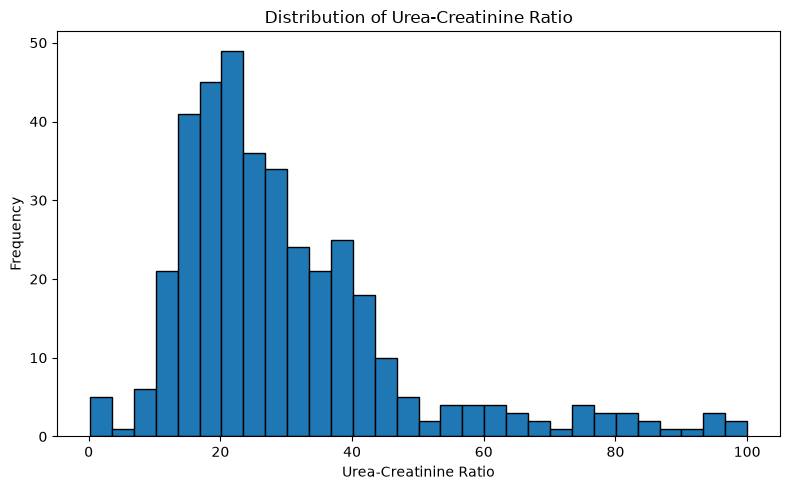

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df_fe["urea_creatinine_ratio"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Urea-Creatinine Ratio")
plt.xlabel("Urea-Creatinine Ratio")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Compare against the target

In [12]:
display(
    df_fe.groupby("class")["urea_creatinine_ratio"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
ckd,236.0,23.02,9.38,0.21,16.84,22.22,28.39,67.0
notckd,144.0,42.14,21.71,8.33,26.59,38.33,50.36,100.0



**Observations**

- The Urea-Creatinine Ratio showed a right-skewed distribution, with most values concentrated between 15 and 40.

- A comparison between the target classes revealed different distributions. The CKD group had a median ratio of 22.22, while the non-CKD group had a median of 38.33.

- This suggests that the new feature captures a potentially useful distinction between the two classes. It will be retained as a candidate for further feature selection and model evaluation.


### Visualise the class differences

<Figure size 700x500 with 0 Axes>

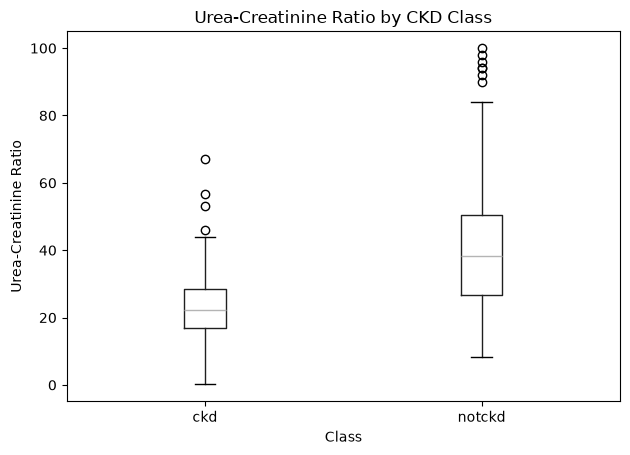

In [13]:
plt.figure(figsize=(7, 5))

df_fe.boxplot(
    column="urea_creatinine_ratio",
    by="class",
    grid=False
)

plt.title("Urea-Creatinine Ratio by CKD Class")
plt.suptitle("")
plt.xlabel("Class")
plt.ylabel("Urea-Creatinine Ratio")
plt.tight_layout()
plt.show()


**Boxplot Analysis**

The boxplot shows a difference in the Urea-Creatinine Ratio between the two classes. The non-CKD group has a higher median and wider distribution than the CKD group.

Both groups contain outliers and some overlap in their distributions.

The feature will be retained as a candidate for further evaluation to determine whether it contributes to model performance.



## Feature Engineering 3: Log Transformation of Blood Urea and Serum Creatinine

### Objective
Apply logarithmic transformations to blood urea (`bu`) and serum creatinine (`sc`) to reduce skewness in their distributions.

### Transformation

The log1p transformation is used:


$$X_{\text{new}} = \log(1 + X)$$


Two new features will be created:
- `log_bu`
- `log_sc`

### Expected Benefit
Log transformation can reduce the influence of extreme values, compress large observations and produce more balanced feature distributions.

### Evaluation
The original and transformed distributions will be compared using histograms and skewness values to determine whether the transformations are useful.


### Check the original distributions

In [14]:
# Examine skewness of original features
print("Blood Urea skewness:", df_fe["bu"].skew())
print("Serum Creatinine skewness:", df_fe["sc"].skew())

Blood Urea skewness: 2.634374458590386
Serum Creatinine skewness: 7.509538252140636


### Visualise the original distributions

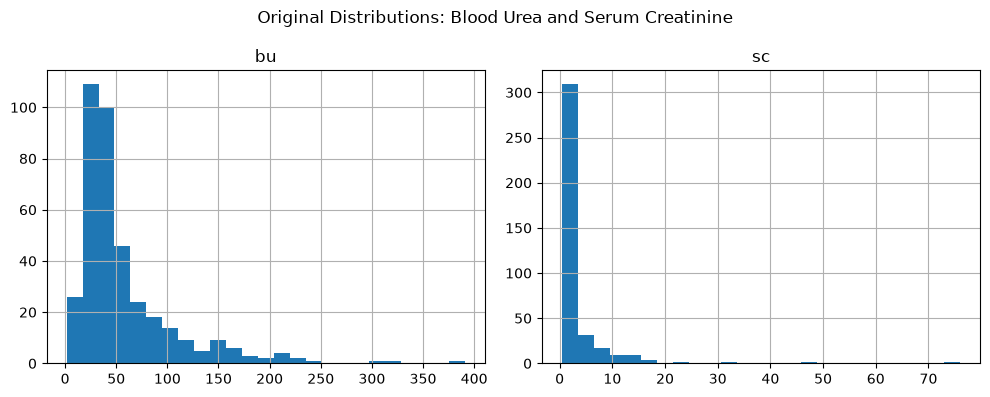

In [15]:
import matplotlib.pyplot as plt

df_fe[["bu", "sc"]].hist(
    bins=25,
    figsize=(10, 4)
)

plt.suptitle("Original Distributions: Blood Urea and Serum Creatinine")
plt.tight_layout()
plt.show()

### Apply log transformation

In [16]:
# Apply log transformation
df_fe["log_bu"] = np.log1p(df_fe["bu"])
df_fe["log_sc"] = np.log1p(df_fe["sc"])

### Compare skewness before and after

In [17]:
skewness_comparison = pd.DataFrame({
    "Original Skewness": [
        df_fe["bu"].skew(),
        df_fe["sc"].skew()
    ],
    "Transformed Skewness": [
        df_fe["log_bu"].skew(),
        df_fe["log_sc"].skew()
    ]
}, index=["Blood Urea", "Serum Creatinine"])

display(skewness_comparison.round(3))

,Original Skewness,Transformed Skewness
Blood Urea,2.634,0.393
Serum Creatinine,7.510,1.612


### Visualise transformed distributions

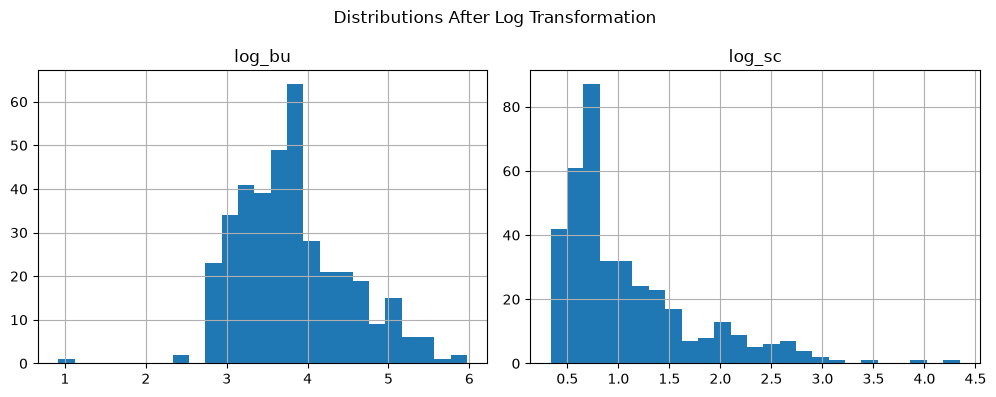

In [18]:
df_fe[["log_bu", "log_sc"]].hist(
    bins=25,
    figsize=(10, 4)
)

plt.suptitle("Distributions After Log Transformation")
plt.tight_layout()
plt.show()


**Observations**

Log transformation reduced the skewness of both features.

- Blood Urea skewness decreased from 2.634 to 0.393.
- Serum Creatinine skewness decreased from 7.510 to 1.612.

The transformed histograms show improved distributions, particularly for Blood Urea. Serum Creatinine still exhibits some positive skewness.

Both transformed features will be retained as candidates for further feature selection and model evaluation.



## Feature Engineering 4: Urine Abnormality Score

### Objective
Create a combined feature using albumin (`al`) and sugar (`su`) urine-test measurements.

### Calculation


$$\text{Urine Abnormality Score} = al + su$$


Both original features use ordinal grades ranging from 0 to 5. The combined score can range from 0 to 10.

### Expected Benefit
This feature aims to capture the combined levels of albumin and sugar in urine rather than considering them independently.

### Evaluation
The new feature will be examined through descriptive statistics, distribution visualisation and comparison between the target classes.

The feature will be treated as an experimental candidate because combining ordinal grades assumes that their contributions can be added meaningfully.


### Create the new feature

In [19]:
# Create combined urine abnormality score
df_fe["urine_abnormality_score"] = (
    df_fe["al"] + df_fe["su"]
)

### Examine the new feature

In [20]:
display(
    df_fe["urine_abnormality_score"].describe().round(2)
)

count    351.00
mean       1.46
std        1.96
min        0.00
25%        0.00
50%        0.00
75%        3.00
max        8.00
Name: urine_abnormality_score, dtype: float64

### Compare by target class

In [21]:
display(
    df_fe.groupby("class")["urine_abnormality_score"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
ckd,206.0,2.48,2.0,0.0,1.0,2.0,4.0,8.0
notckd,145.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0



**Observations**

- The combined Urine Abnormality Score showed a strong difference between the two classes. The CKD group had a mean score of 2.48, while all non-CKD records had a score of 0.

- This suggests that the feature captures a potentially useful relationship with CKD classification. It will be retained as a candidate for further feature selection and model evaluation.


### Visualise the feature distribution
Since this is a discrete score, let's use a count plot.

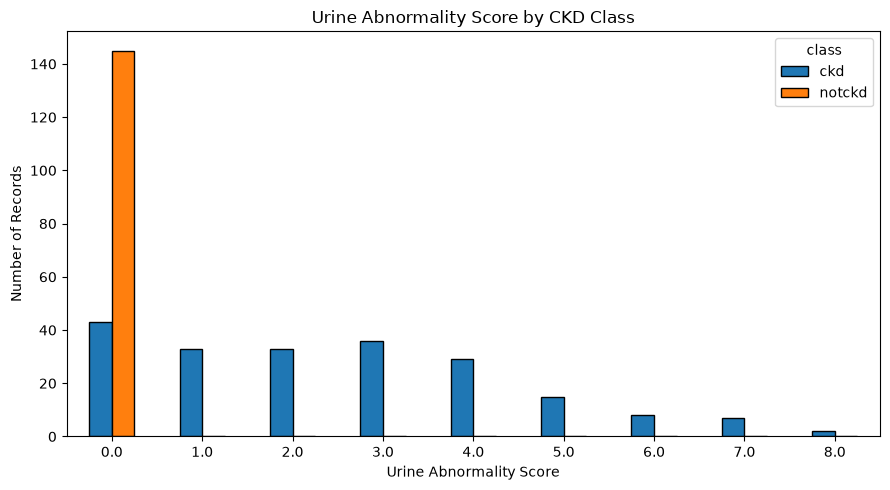

In [22]:
score_counts = pd.crosstab(
    df_fe["urine_abnormality_score"],
    df_fe["class"]
)

score_counts.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

plt.title("Urine Abnormality Score by CKD Class")
plt.xlabel("Urine Abnormality Score")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Distribution Analysis**

The count plot confirms a strong association between the Urine Abnormality Score and CKD classification. All non-CKD records have a score of 0, while CKD records have scores ranging from 0 to 8.

This feature will be retained as a candidate for further feature selection and comparative model evaluation.



## Feature Engineering 5: Blood Urea and Serum Creatinine Interaction

### Objective
Create an interaction feature by combining blood urea (`bu`) and serum creatinine (`sc`).

### Calculation


$$\text{BU-SC Interaction} = bu \times sc$$


### Expected Benefit
This feature aims to capture the combined effect of blood urea and serum creatinine measurements. It allows ML models to explore relationships between these variables that may not be captured by considering them independently.

### Evaluation
The new feature will be examined through descriptive statistics, distribution visualisation and comparison between CKD and non-CKD classes.

The feature will be treated as an experimental candidate and evaluated for its contribution to model performance.


### Create the interaction feature

In [23]:
# Create Blood Urea and Serum Creatinine interaction
df_fe["bu_sc_interaction"] = (
    df_fe["bu"] * df_fe["sc"]
)

### Examine the new feature

In [24]:
display(
    df_fe["bu_sc_interaction"].describe().round(2)
)

count      380.00
mean       343.94
std       1122.29
min          5.00
25%         24.45
50%         49.25
75%        182.00
max      13680.00
Name: bu_sc_interaction, dtype: float64

### Compare by target class

In [25]:
display(
    df_fe.groupby("class")["bu_sc_interaction"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
ckd,236.0,536.59,1390.27,8.0,46.60,119.25,414.5,13680.0
notckd,144.0,28.20,12.93,5.0,19.15,25.10,36.0,60.0



**Observations**

The Blood Urea and Serum Creatinine interaction showed a considerable difference between the two classes. The CKD group had a median value of 119.25, compared with 25.10 for the non-CKD group.

The CKD group also showed substantial variability and extreme values.

This feature will be retained as a candidate for further feature selection and model evaluation.


### Visualise the interaction
Because the CKD values have a much wider range, we'll use a logarithmic y-axis to make the distributions easier to compare.

<Figure size 700x500 with 0 Axes>

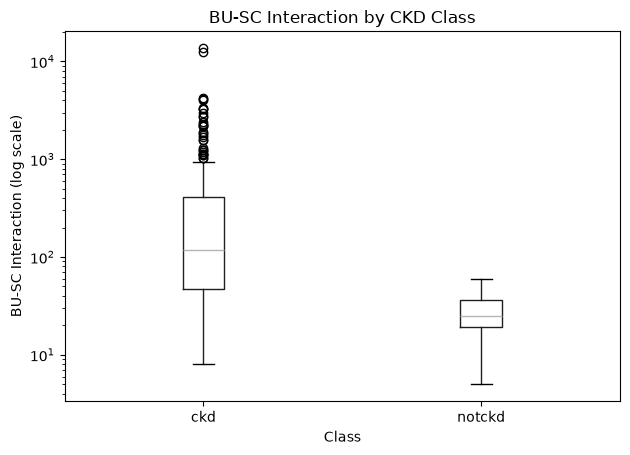

In [26]:
plt.figure(figsize=(7, 5))

df_fe.boxplot(
    column="bu_sc_interaction",
    by="class",
    grid=False
)

plt.yscale("log")
plt.title("BU-SC Interaction by CKD Class")
plt.suptitle("")
plt.xlabel("Class")
plt.ylabel("BU-SC Interaction (log scale)")
plt.tight_layout()
plt.show()


**Boxplot Analysis**

The boxplot shows a noticeable difference between the two classes. CKD records have a substantially higher median interaction value and greater variability, with several extreme outliers.

The non-CKD group has a lower and more compact distribution. This suggests that the interaction feature may capture useful information for distinguishing between the classes.

The feature will be retained as a candidate for further evaluation.



## Export Feature-Engineered Dataset

A new dataset containing the original features and newly engineered features was created and exported as a CSV file.

The dataset was saved in a separate `2_feature_engineered_data` folder to preserve the original data and allow further feature selection and evaluation.

**Output:** `DS1_feature_engineered.csv`


In [27]:
display(df_fe.head(10))

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,appet,pe,ane,class,comorbidity_count,urea_creatinine_ratio,log_bu,log_sc,urine_abnormality_score,bu_sc_interaction
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,good,no,no,ckd,2.0,30.000000,3.610918,0.788457,1.0,43.2
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,good,no,no,ckd,0.0,22.500000,2.944439,0.587787,4.0,14.4
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,poor,no,yes,ckd,1.0,29.444444,3.988984,1.029619,5.0,95.4
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,poor,yes,yes,ckd,1.0,14.736842,4.043051,1.568616,4.0,212.8
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,good,no,no,ckd,0.0,18.571429,3.295837,0.875469,2.0,36.4
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,...,good,yes,no,ckd,2.0,22.727273,3.258097,0.741937,3.0,27.5
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,...,good,no,no,ckd,0.0,2.250000,4.007333,3.218876,0.0,1296.0
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,...,good,yes,no,ckd,1.0,28.181818,3.465736,0.741937,6.0,34.1
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,...,good,no,yes,ckd,2.0,31.578947,4.110874,1.064711,3.0,114.0
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,...,poor,no,yes,ckd,2.0,14.861111,4.682131,2.104134,2.0,770.4


In [28]:
from pathlib import Path

# Create output folder
output_dir = Path(
    "../../../assets/datasets/1_UCI_Chronic_Kidney_Disease_Dataset/2_feature_engineered_data"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Save feature-engineered dataset
output_file = output_dir / "DS1_feature_engineered.csv"

df_fe.to_csv(output_file, index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [29]:
print("File exists:", output_file.exists())
print("Dataset shape:", df_fe.shape)
print("Total missing values:", df_fe.isnull().sum().sum())


File exists: True
Dataset shape: (400, 31)
Total missing values: 1139
